# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** Fernanda Brittes, Willian e Gabriel · **Tema:** Estágio (chatbot "Estagi")

---

Notebook **entregável** do grupo. Roda do início ao fim ("Kernel → Restart & Run All")
e **regera os modelos** salvos em `modelos/`. Segue a estrutura do
`00_exemplo_biblioteca.ipynb`.

* `📝 RELATÓRIO` - resultado que aparece (e é discutido) no artigo.

---
## 0. Ambiente

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# (só para o Colab) endereço do repositório do grupo
REPO_URL = "https://github.com/willfeerr/Est-gio-IA-2026-02-TP-Chatbot.git"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO
from chatbot.texto import normalizar

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

---
## 1. Configuração

Tema **Estágio**: o bot atende estudantes de graduação da UFMS. As 8 intenções
foram definidas a partir dos assuntos do Regulamento de Estágio (Resolução nº
706-COGRAD/UFMS/2022) e da Lei nº 11.788/2008, procurando fronteiras que uma pessoa
consiga rotular sem hesitar.

In [3]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema, "| limiar_tema:", config.limiar_tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])

Grupo: Grupo Estágio | Tema: Estágio | limiar_tema: 0.35


,intenção,descrição
0,tipos_estagio,estágio obrigatório e não obrigatório e quem pode estagiar
1,vagas_convenio,"vagas de estágio, empresas concedentes, convênios e agentes de integração"
2,termo_compromisso,"termo de compromisso (TCE), assinaturas, termo aditivo e rescisão"
3,carga_horaria,"jornada, carga horária, duração máxima e recesso do estágio"
4,bolsa_auxilio,"bolsa, remuneração e auxílio-transporte"
5,seguro,seguro contra acidentes pessoais do estagiário
6,orientador_supervisor,"professor orientador, supervisor de estágio e Comissão de Estágio (COE)"
7,relatorio_avaliacao,"relatórios de atividades, avaliação e conclusão do estágio"


---
## 2. Dados

**Como os dados foram construídos** (detalhes no artigo e em `dados/README.md`):

* **LLM (`origem = llm`)** - `openai/gpt-6-luna` via OpenRouter, com
  `scripts/gerar_dados_llm.py` (5 estilos × 14 frases por intenção, chitchat e
  fora_dominio) e `scripts/gerar_negativos_dificeis.py` (perguntas dos **temas dos
  outros grupos** que usam palavras do nosso tema: *bolsa, termo, seguro, carga
  horária, relatório, orientador, convênio...*). Todos os prompts estão em
  `dados/prompts_llm.md`. **Todas** as frases foram revisadas; as descartadas e o
  motivo estão em `dados/descartadas_llm.txt`.
* **MASSIVE (`origem = massive`)** - amostra de 120 chitchat e 250 fora_dominio
  (`scripts/baixar_massive.py`): negativos fáceis, em português de Portugal.
* **Humano (`origem = humano`)** - frases do formulário (Google Forms) respondido
  por colegas e frases escritas pelos integrantes (`dados/humano_treino.csv`).
* **Teste** - somente frases escritas por pessoas (`dados/humano_teste.csv`),
  separadas do treino antes de qualquer experimento.

`scripts/montar_treino.py` junta as fontes, remove duplicatas e garante que
nenhuma frase do teste esteja no treino.

📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

In [4]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
TEM_TESTE = len(teste) > 0
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
if TEM_TESTE:
    print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
    print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
else:
    print("ATENÇÃO: dados/teste.csv ainda está vazio (aguardando o formulário).")
display(resumo(treino))
if TEM_TESTE:
    display(resumo(teste))

Problemas no treino: nenhum
ATENÇÃO: dados/teste.csv ainda está vazio (aguardando o formulário).


origem,llm,massive,total
intencao,,,
bolsa_auxilio,67,0,67
carga_horaria,68,0,68
chitchat,53,120,173
fora_dominio,268,250,518
orientador_supervisor,70,0,70
relatorio_avaliacao,70,0,70
seguro,71,0,71
termo_compromisso,70,0,70
tipos_estagio,67,0,67


### 2.1 Análise exploratória

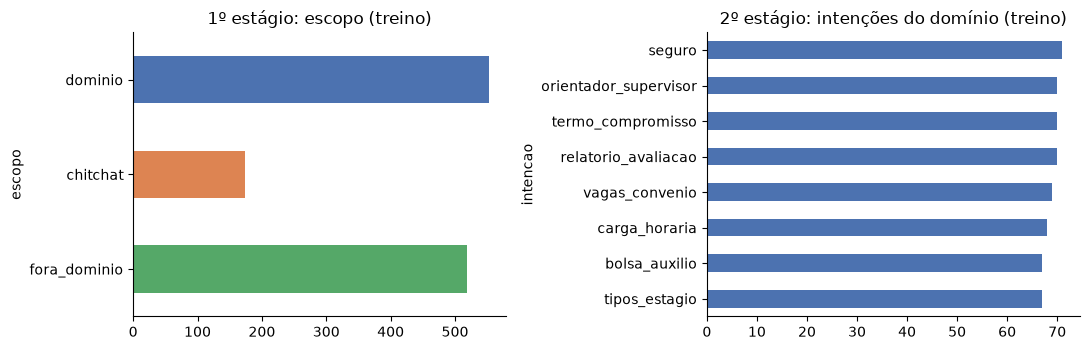

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6))
treino["escopo"].value_counts().reindex(CLASSES_ESCOPO).plot.barh(ax=eixos[0], color=CORES[:3])
eixos[0].set_title("1º estágio: escopo (treino)")
eixos[0].invert_yaxis()
treino.loc[treino["escopo"] == "dominio", "intencao"].value_counts().plot.barh(ax=eixos[1], color=CORES[0])
eixos[1].set_title("2º estágio: intenções do domínio (treino)")
eixos[1].invert_yaxis()
plt.tight_layout()
plt.show()

In [6]:
# tamanho das mensagens (em palavras) por classe e por origem
treino = treino.assign(n_palavras=treino["texto"].str.split().str.len())
display(treino.groupby("intencao")["n_palavras"].describe()[["mean", "50%", "min", "max"]].round(1))
display(treino.groupby("origem")["n_palavras"].describe()[["count", "mean", "50%"]].round(1))

,mean,50%,min,max
intencao,,,,
bolsa_auxilio,9.7,8.0,2.0,21.0
carga_horaria,11.0,9.0,3.0,28.0
chitchat,6.1,5.0,1.0,21.0
fora_dominio,9.6,9.0,1.0,32.0
orientador_supervisor,10.5,9.5,3.0,23.0
relatorio_avaliacao,10.5,10.0,3.0,23.0
seguro,10.1,10.0,3.0,20.0
termo_compromisso,10.8,10.0,3.0,24.0
tipos_estagio,9.4,9.0,2.0,19.0


,count,mean,50%
origem,,,
llm,873.0,10.5,10.0
massive,370.0,7.2,7.0


In [7]:
# palavras mais frequentes por intenção (sem stopwords, sem acento)
from collections import Counter

from chatbot.texto import STOPWORDS

def top_palavras(textos, k=8):
    c = Counter(w for t in textos for w in normalizar(t).split() if w not in STOPWORDS and len(w) > 2)
    return ", ".join(w for w, _ in c.most_common(k))

pd.DataFrame({"palavras mais frequentes": treino.groupby("intencao")["texto"].apply(top_palavras)})

,palavras mais frequentes
intencao,
bolsa_auxilio,"bolsa, auxilio, transporte, valor, pagamento, como, pode, nao"
carga_horaria,"estagio, recesso, pode, horas, posso, tempo, jornada, limite"
chitchat,"dia, hoje, como, bom, olly, sobre, qual, voce"
fora_dominio,"como, qual, preciso, nao, horas, algum, posso, auxilio"
orientador_supervisor,"orientador, supervisor, estagio, professor, quem, coe, pode, como"
relatorio_avaliacao,"relatorio, como, estagio, atividades, final, avaliacao, posso, devo"
seguro,"seguro, acidente, cobre, como, acidentes, cobertura, seguradora, durante"
termo_compromisso,"tce, termo, aditivo, como, assinatura, assinar, mas, assinado"
tipos_estagio,"estagio, obrigatorio, pode, estagiar, nao, fazer, curso, posso"


In [8]:
# exemplos de negativos difíceis (fora_dominio com palavras típicas do tema)
gatilhos = ["bolsa", "termo", "seguro", "carga horaria", "relatorio", "orientador", "convenio", "auxilio"]
norm = treino["texto"].map(normalizar)
mask = (treino["intencao"] == "fora_dominio") & norm.apply(lambda t: any(g in t for g in gatilhos))
print(f"{mask.sum()} frases fora_dominio contêm palavras do tema. Exemplos:")
treino.loc[mask, ["texto", "origem"]].sample(12, random_state=RANDOM_STATE)

103 frases fora_dominio contêm palavras do tema. Exemplos:


,texto,origem
380,A universidade tem convênio com instituições que oferecem atividades válidas para comp...,llm
793,Como faço pra pedir auxílio alimentação? Precisa enviar documentos pelo sistema?,llm
757,Você poderia me explicar como devo entregar o relatório da minha pesquisa de iniciação...,llm
525,Preciso entregar relatório parcial da iniciação científica? Qual é o prazo?,llm
506,Existe auxílio para a equipe viajar para os jogos universitários?,llm
492,"meu orientador ainda nao confirmou a data da defesa, tem prazo pra marcar?",llm
1053,Seguro do carro,llm
516,"preciso baixar um relatório das minhas notas no moodle, onde fica essa opção?",llm
98,O termo de compromisso do auxílio permanência precisa da assinatura de algum responsável?,llm
6,O valor do auxílio alimentação mudou neste ano? Onde encontro essa informação?,llm


---
## 3. Representações de texto

Três representações, todas com a normalização do código base (minúsculas, sem
acento, sem pontuação):

* **TF-IDF palavras (1-2 gramas)** - padrão de `tfidf_palavras()`;
* **TF-IDF palavras (só unigramas, min_df=2)** - vocabulário menor;
* **TF-IDF caracteres (2-5 gramas)** - robusto a erros de digitação ("estagio",
  "estájio", "tce").

In [9]:
REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF palavras (unigramas)": lambda: tfidf_palavras(ngram_range=(1, 1), min_df=2),
    "TF-IDF caracteres": tfidf_caracteres,
}
corpus = treino["texto"].tolist()
for nome, rep in REPRESENTACOES.items():
    print(f"{nome:30s}: {rep().fit_transform(corpus).shape[1]:6d} dimensões")

TF-IDF palavras               :   8305 dimensões


TF-IDF palavras (unigramas)   :    967 dimensões


TF-IDF caracteres             :  13039 dimensões


---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

Quatro algoritmos × três representações, validação cruzada estratificada com 5
folds **só no treino**. Regressão logística, MLP e árvore de decisão foram vistos
em aula; Naive Bayes multinomial entra como um quarto candidato (caixa-preta
explicada no artigo).

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Regressão logística,0.806,0.034,0.854,0.999
1,TF-IDF caracteres,Rede neural (MLP),0.806,0.030,0.850,1.000
2,TF-IDF palavras,Rede neural (MLP),0.800,0.042,0.847,1.000
3,TF-IDF palavras (unigramas),Regressão logística,0.796,0.037,0.847,0.983
4,TF-IDF palavras (unigramas),Rede neural (MLP),0.796,0.028,0.837,0.994
5,TF-IDF palavras,Regressão logística,0.794,0.031,0.854,1.000
6,TF-IDF caracteres,Naive Bayes,0.781,0.047,0.833,0.966
7,TF-IDF palavras (unigramas),Naive Bayes,0.768,0.024,0.825,0.931
8,TF-IDF palavras,Naive Bayes,0.766,0.038,0.826,0.999
9,TF-IDF palavras (unigramas),Árvore de decisão,0.718,0.021,0.759,0.994


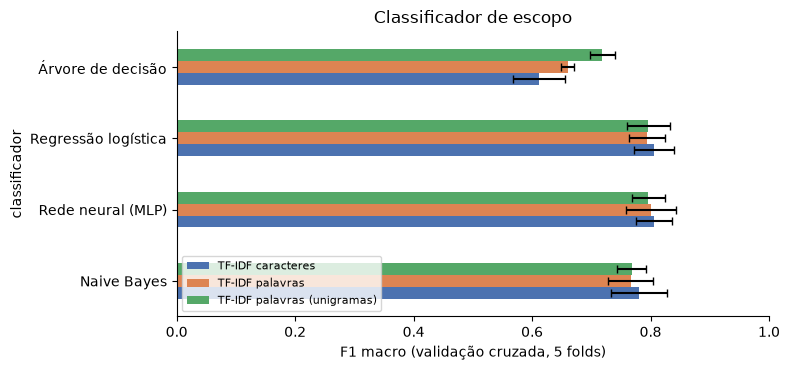

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600,
                                               random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Naive Bayes": lambda: MultinomialNB(alpha=0.1),
}


def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"],
                               return_train_score=True, n_jobs=-1)
            linhas.append({"representação": nome_rep, "classificador": nome_clf,
                           "F1 macro (CV)": r["test_f1_macro"].mean(), "desvio": r["test_f1_macro"].std(),
                           "acurácia (CV)": r["test_accuracy"].mean(),
                           "F1 macro (treino)": r["train_f1_macro"].mean()})
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)


def grafico_comparacao(tab, titulo):
    piv = tab.pivot(index="classificador", columns="representação", values="F1 macro (CV)")
    err = tab.pivot(index="classificador", columns="representação", values="desvio")
    ax = piv.plot.barh(xerr=err, color=CORES[:3], figsize=(8, 3.8), capsize=3)
    ax.set_xlabel("F1 macro (validação cruzada, 5 folds)")
    ax.set_xlim(0, 1)
    ax.set_title(titulo)
    ax.legend(loc="lower left", fontsize=8)
    plt.tight_layout()
    plt.show()


tab_escopo = comparar(treino["texto"], treino["escopo"])
display(tab_escopo.round(3))
grafico_comparacao(tab_escopo, "Classificador de escopo")

### 4.1 Ajuste de hiperparâmetros e curva de validação

Ajustamos os dois melhores algoritmos com `GridSearchCV` (só no treino): regressão
logística (C e faixa de n-gramas) e MLP (tamanho da camada e regularização α).

In [11]:
busca_escopo = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=3000))]),
    param_grid={"classificador__C": [0.01, 0.1, 1, 10, 100, 1000],
                "vetorizador__ngram_range": [(2, 4), (2, 5)]},
    scoring="f1_macro", cv=cv, return_train_score=True, n_jobs=-1,
)
busca_escopo.fit(treino["texto"], treino["escopo"])
print("Regressão logística:", busca_escopo.best_params_, round(busca_escopo.best_score_, 3))

busca_escopo_mlp = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),
              ("classificador", MLPClassifier(max_iter=600, random_state=RANDOM_STATE))]),
    param_grid={"classificador__hidden_layer_sizes": [(32,), (64,)],
                "classificador__alpha": [1e-4, 1e-2, 1]},
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_escopo_mlp.fit(treino["texto"], treino["escopo"])
print("MLP:", busca_escopo_mlp.best_params_, round(busca_escopo_mlp.best_score_, 3))

Regressão logística: {'classificador__C': 10, 'vetorizador__ngram_range': (2, 4)} 0.819


MLP: {'classificador__alpha': 0.01, 'classificador__hidden_layer_sizes': (64,)} 0.812


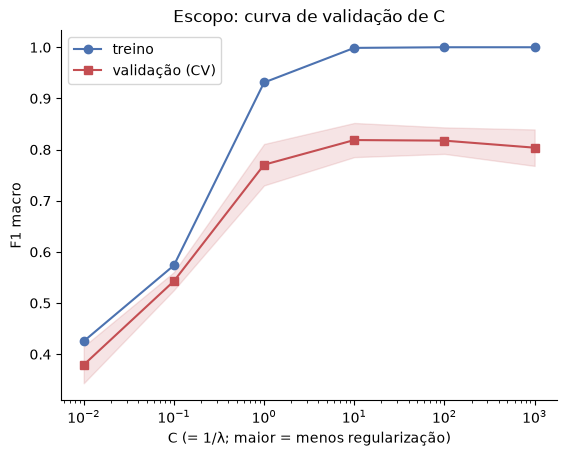

In [12]:
def curva_validacao(busca, titulo, filtro=None):
    res = pd.DataFrame(busca.cv_results_)
    if filtro:
        for k, v in filtro.items():
            res = res[res[k].astype(str) == str(v)]
    c = res["param_classificador__C"].astype(float)
    ax = plt.gca()
    ax.semilogx(c, res["mean_train_score"], "o-", color=CORES[0], label="treino")
    ax.semilogx(c, res["mean_test_score"], "s-", color=CORES[3], label="validação (CV)")
    ax.fill_between(c, res["mean_test_score"] - res["std_test_score"],
                    res["mean_test_score"] + res["std_test_score"], color=CORES[3], alpha=0.15)
    ax.set_xlabel("C (= 1/λ; maior = menos regularização)")
    ax.set_ylabel("F1 macro")
    ax.set_title(titulo)
    ax.legend()
    plt.show()


curva_validacao(busca_escopo, "Escopo: curva de validação de C",
                {"param_vetorizador__ngram_range": busca_escopo.best_params_["vetorizador__ngram_range"]})

In [13]:
# escolha do modelo final de escopo: o de maior F1 macro na CV
clf_escopo = (busca_escopo if busca_escopo.best_score_ >= busca_escopo_mlp.best_score_
              else busca_escopo_mlp).best_estimator_
print("Escopo escolhido:", clf_escopo.named_steps["classificador"])

Escopo escolhido: LogisticRegression(C=10, max_iter=3000)


### 4.2 Matriz de confusão, falso aceite e falsa recusa

📝 RELATÓRIO: no tema estágio, o **falso aceite** (responder com regras de estágio
uma pergunta sobre bolsa de monitoria, auxílio da assistência estudantil ou
orientador de TCC) é o erro mais grave: o estudante recebe uma regra **errada**
com confiança, por exemplo sobre valor de bolsa ou prazo. A **falsa recusa** só
faz o estudante reformular ou procurar a COE.

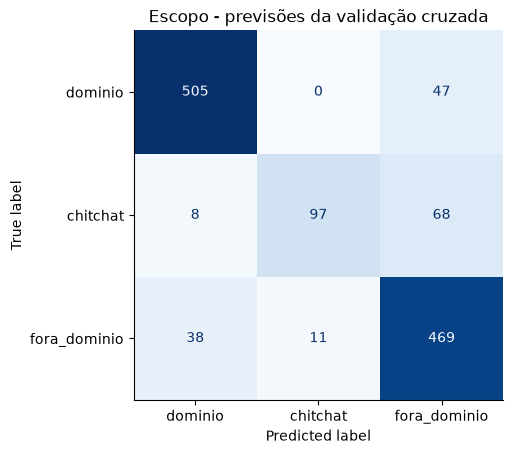

falso aceite  (neg. previstos como dominio): 0.067
falsa recusa  (dominio previsto como outro): 0.085

Erros por origem:


,erros,total,taxa
origem,,,
llm,96,873,0.110
massive,76,370,0.205


,texto,escopo,previsto,origem
0,eu quero que analises o padrão para comprar um bilhete de lotaria em que o número vai ...,chitchat,fora_dominio,massive
4,és real,chitchat,dominio,massive
7,a fazer cálculos muito complexos como jarvins,chitchat,fora_dominio,massive
31,podes dizer-me a solução para resolver as alterações climáticas,chitchat,fora_dominio,massive
32,eu espero que pudéssemos almoçar juntos,chitchat,fora_dominio,massive
...,...,...,...,...
1210,"Você é meu único colega acordado nessa madrugada, né? Estou aqui tentando revisar tudo...",chitchat,fora_dominio,llm
1211,encontra a cópia mais barata de ama te,chitchat,fora_dominio,massive
1213,podes criar uma dieta sem acúcar para mim e criar uma lista de compras para os ingredi...,chitchat,fora_dominio,massive
1225,acorda siri,chitchat,fora_dominio,massive


In [14]:
prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.title("Escopo - previsões da validação cruzada")
plt.grid(False)
plt.show()

real = treino["escopo"].to_numpy()
neg = real != "dominio"
print(f"falso aceite  (neg. previstos como dominio): {(prev_cv[neg] == 'dominio').mean():.3f}")
print(f"falsa recusa  (dominio previsto como outro): {(prev_cv[~neg] != 'dominio').mean():.3f}")
erros_escopo = treino.assign(previsto=prev_cv).query("escopo != previsto")
print("\nErros por origem:")
display(erros_escopo["origem"].value_counts().to_frame("erros").join(treino["origem"].value_counts().rename("total"))
        .assign(taxa=lambda d: (d["erros"] / d["total"]).round(3)))
erros_escopo[["texto", "escopo", "previsto", "origem"]]

---
## 5. Classificador de tema (intenções do domínio)

Mesma metodologia, treinando **só** com as mensagens do domínio.

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF palavras,Regressão logística,0.982,0.013,0.982,1.000
1,TF-IDF caracteres,Naive Bayes,0.982,0.013,0.982,0.998
2,TF-IDF caracteres,Regressão logística,0.980,0.016,0.980,1.000
3,TF-IDF caracteres,Rede neural (MLP),0.978,0.012,0.978,1.000
4,TF-IDF palavras (unigramas),Regressão logística,0.972,0.017,0.973,1.000
5,TF-IDF palavras (unigramas),Rede neural (MLP),0.969,0.017,0.969,1.000
6,TF-IDF palavras,Rede neural (MLP),0.969,0.014,0.969,1.000
7,TF-IDF palavras,Naive Bayes,0.961,0.010,0.962,1.000
8,TF-IDF palavras (unigramas),Naive Bayes,0.942,0.016,0.942,0.991
9,TF-IDF palavras (unigramas),Árvore de decisão,0.907,0.017,0.904,1.000


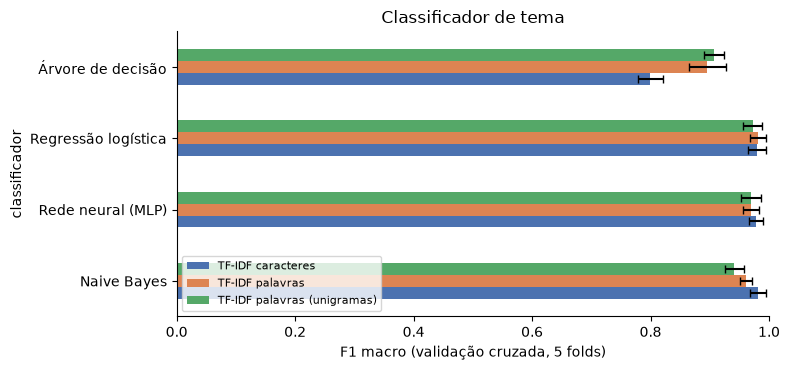

In [15]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
display(tab_tema.round(3))
grafico_comparacao(tab_tema, "Classificador de tema")

Regressão logística: {'classificador__C': 10, 'vetorizador__ngram_range': (2, 4)} 0.98


MLP: {'classificador__alpha': 0.01, 'classificador__hidden_layer_sizes': (32,)} 0.98


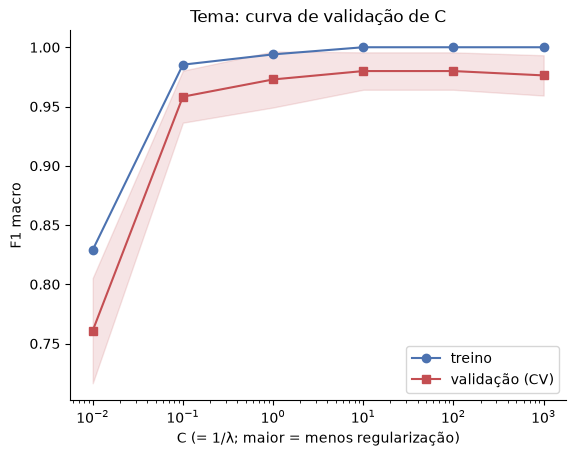

Tema escolhido: LogisticRegression(C=10, max_iter=3000)


In [16]:
busca_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=3000))]),
    param_grid={"classificador__C": [0.01, 0.1, 1, 10, 100, 1000],
                "vetorizador__ngram_range": [(2, 4), (2, 5)]},
    scoring="f1_macro", cv=cv, return_train_score=True, n_jobs=-1,
)
busca_tema.fit(treino_dom["texto"], treino_dom["intencao"])
print("Regressão logística:", busca_tema.best_params_, round(busca_tema.best_score_, 3))

busca_tema_mlp = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),
              ("classificador", MLPClassifier(max_iter=600, random_state=RANDOM_STATE))]),
    param_grid={"classificador__hidden_layer_sizes": [(32,), (64,)],
                "classificador__alpha": [1e-4, 1e-2, 1]},
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_tema_mlp.fit(treino_dom["texto"], treino_dom["intencao"])
print("MLP:", busca_tema_mlp.best_params_, round(busca_tema_mlp.best_score_, 3))

curva_validacao(busca_tema, "Tema: curva de validação de C",
                {"param_vetorizador__ngram_range": busca_tema.best_params_["vetorizador__ngram_range"]})

clf_tema = (busca_tema if busca_tema.best_score_ >= busca_tema_mlp.best_score_
            else busca_tema_mlp).best_estimator_
print("Tema escolhido:", clf_tema.named_steps["classificador"])

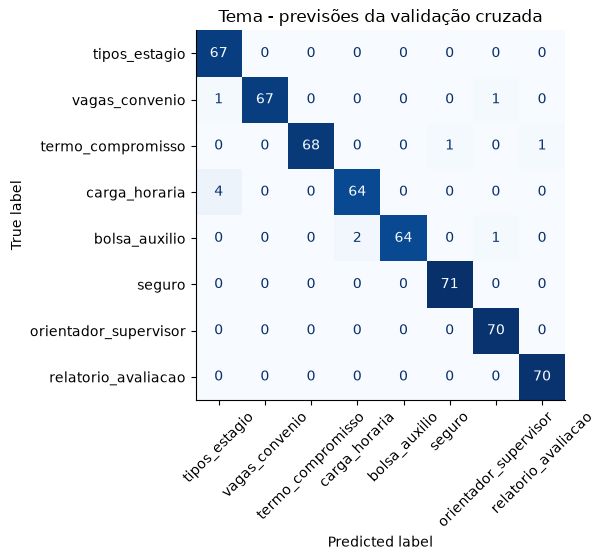

                       precision    recall  f1-score   support

        bolsa_auxilio       1.00      0.96      0.98        67
        carga_horaria       0.97      0.94      0.96        68
orientador_supervisor       0.97      1.00      0.99        70
  relatorio_avaliacao       0.99      1.00      0.99        70
               seguro       0.99      1.00      0.99        71
    termo_compromisso       1.00      0.97      0.99        70
        tipos_estagio       0.93      1.00      0.96        67
       vagas_convenio       1.00      0.97      0.99        69

             accuracy                           0.98       552
            macro avg       0.98      0.98      0.98       552
         weighted avg       0.98      0.98      0.98       552



In [17]:
prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.title("Tema - previsões da validação cruzada")
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

In [18]:
# 📝 RELATÓRIO: pares de intenções que mais se confundem
pares = (treino_dom.assign(previsto=prev_tema).query("intencao != previsto")
         .groupby(["intencao", "previsto"]).size().sort_values(ascending=False).head(8))
display(pares.to_frame("erros"))
treino_dom.assign(previsto=prev_tema).query("intencao != previsto")[["texto", "intencao", "previsto"]]

erros
intencao          previsto                    
carga_horaria     tipos_estagio              4
bolsa_auxilio     carga_horaria              2
                  orientador_supervisor      1
termo_compromisso relatorio_avaliacao        1
                  seguro                     1
vagas_convenio    orientador_supervisor      1
                  tipos_estagio              1

,texto,intencao,previsto
23,Estágio pode ser integral?,carga_horaria,tipos_estagio
45,Estágio pode ser remunerado por hora?,bolsa_auxilio,carga_horaria
142,Recesso é obrigatório?,carga_horaria,tipos_estagio
282,Como faço pra buscar estágio na minha área?,vagas_convenio,orientador_supervisor
296,É necessário entregar uma via do TCE para cada parte envolvida?,termo_compromisso,relatorio_avaliacao
329,o estagiario recebe decimo terceiro,bolsa_auxilio,carga_horaria
490,Quais informações e documentos preciso apresentar para que o TCE seja elaborado corret...,termo_compromisso,seguro
616,Buscar estágio pelo Nube,vagas_convenio,tipos_estagio
785,Estagiário pode fazer 8h por dia?,carga_horaria,tipos_estagio
980,"Caso haja atraso no pagamento, qual canal devo procurar para obter orientação?",bolsa_auxilio,orientador_supervisor


In [19]:
# termos de maior peso por intenção (modelo interpretável: logística com TF-IDF de palavras)
interpretavel = Pipeline([("vetorizador", tfidf_palavras()),
                          ("classificador", LogisticRegression(C=10, max_iter=2000))])
interpretavel.fit(treino_dom["texto"], treino_dom["intencao"])
termos = interpretavel["vetorizador"].get_feature_names_out()
pesos = interpretavel["classificador"].coef_
pd.DataFrame({c: [termos[j] for j in np.argsort(pesos[i])[::-1][:8]]
              for i, c in enumerate(interpretavel["classificador"].classes_)})

,bolsa_auxilio,carga_horaria,orientador_supervisor,relatorio_avaliacao,seguro,termo_compromisso,tipos_estagio,vagas_convenio
0,bolsa,recesso,orientador,relatorio,seguro,tce,obrigatorio,vagas
1,transporte,horas,supervisor,avaliacao,acidente,assinatura,estagiar,empresas
2,valor,jornada,coe,atividades,cobertura,termo,estagio obrigatorio,universidade
3,pagamento,limite,professor orientador,do estagio,seguradora,aditivo,pode estagiar,convenio
4,auxilio,tempo,professor,final,apolice,rescisao,estagio,empresa
5,auxilio transporte,estagio pode,quem,nota,cobre,assinar,fazer estagio,agentes
6,da bolsa,por dia,comissao,de atividades,um acidente,termo de,curso,de integracao
7,receber,maxima,da coe,meu relatorio,seguro cobre,assinado,fazer,integracao


---
## 6. Limiar de confiança

Probabilidades da validação cruzada: para cada limiar, quantas frases o bot
responderia direto, com que acurácia, quantos erros evitaria e quantos acertos
viraria pergunta ("sua dúvida é sobre X ou Y?").

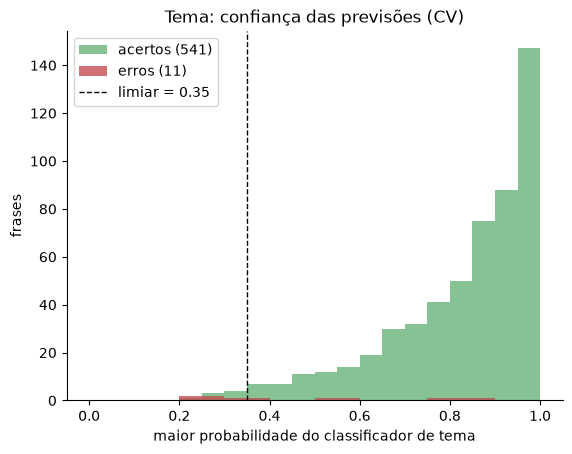

,limiar,% respondidas direto,acurácia nas respondidas,erros evitados,acertos que viraram pergunta
0,0.00,1.000,0.980,0,0
1,0.20,1.000,0.980,0,0
2,0.25,0.995,0.984,2,1
3,0.30,0.986,0.987,4,4
4,0.35,0.976,0.989,5,8
5,0.40,0.962,0.991,6,15
6,0.50,0.929,0.990,6,33
7,0.60,0.879,0.994,8,59


In [20]:
proba_cv = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv,
                             method="predict_proba")
classes = np.array(sorted(treino_dom["intencao"].unique()))
confianca = proba_cv.max(axis=1)
acertou = classes[proba_cv.argmax(axis=1)] == treino_dom["intencao"].to_numpy()

bins = np.linspace(0, 1, 21)
plt.hist(confianca[acertou], bins=bins, alpha=0.7, color=CORES[2], label=f"acertos ({acertou.sum()})")
plt.hist(confianca[~acertou], bins=bins, alpha=0.8, color=CORES[3], label=f"erros ({(~acertou).sum()})")
plt.axvline(config.limiar_tema, color="k", ls="--", lw=1, label=f"limiar = {config.limiar_tema}")
plt.xlabel("maior probabilidade do classificador de tema")
plt.ylabel("frases")
plt.title("Tema: confiança das previsões (CV)")
plt.legend()
plt.show()

linhas = []
for limiar in [0.0, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6]:
    resp = confianca >= limiar
    linhas.append({"limiar": limiar, "% respondidas direto": resp.mean(),
                   "acurácia nas respondidas": acertou[resp].mean() if resp.any() else np.nan,
                   "erros evitados": int((~acertou & ~resp).sum()),
                   "acertos que viraram pergunta": int((acertou & ~resp).sum())})
tab_limiar = pd.DataFrame(linhas)
tab_limiar.round(3)

**Escolha do limiar.** O valor gravado em `roteamento.limiar_tema` (grupo.yaml) é o
que troca a maior quantidade de erros por perguntas sem transformar muitos acertos
em perguntas (ver tabela acima; a justificativa numérica está no artigo). Na
avaliação automática, uma pergunta de esclarecimento conta como erro, por isso o
limiar é conservador.

---
## 7. Salvar os modelos finais

In [21]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # relê, caso o limiar tenha sido alterado
print("Salvos em:", config.modelo_escopo.parent, "| limiar_tema =", config.limiar_tema)

Salvos em: C:\Users\GABRI\OneDrive\Documentos\UFMS\IA\TRABALHO\Est-gio-IA-2026-02-TP-Chatbot\modelos | limiar_tema = 0.35


---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

Documentos em `documentos/` (uma pasta por intenção + `geral/`, fontes em
`documentos/FONTES.md`): Resolução 706-COGRAD, manual do Termo de Compromisso,
IN 11-PROAES (seguro), manual de estágio do CPAQ e resumos escritos pelo grupo a
partir da Lei 11.788/2008. A persona ("Estagi") manda responder só com base nos
trechos e indicar a COE quando não souber.

In [22]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

base = BaseConhecimento.carregar_ou_criar(config)
display(base.resumo())

# teste da busca (não gasta créditos)
for pergunta, intencao in [("quantas horas por dia posso estagiar?", "carga_horaria"),
                           ("quem paga o seguro no estágio não obrigatório?", "seguro"),
                           ("passou do prazo do termo, posso fazer aditivo?", "termo_compromisso")]:
    print(f"\n>>> {pergunta}  [{intencao}]")
    for tr, sim in base.buscar(pergunta, intencao=intencao, k=3):
        print(f"  {sim:.2f}  {tr.fonte} | {tr.texto[:70]!r}")

trechos  \
intencao              fonte                                                                   
bolsa_auxilio         bolsa_auxilio\bolsa_e_auxilio_transporte.md                         8   
carga_horaria         carga_horaria\jornada_duracao_recesso.md                            6   
geral                 geral\perguntas_frequentes_estagio.md                               4   
                      geral\resolucao_706_cograd_2022_regulamento_estagio.pdf            44   
orientador_supervisor orientador_supervisor\orientador_supervisor_coe.md                  6   
relatorio_avaliacao   relatorio_avaliacao\manual_estagio_matematica_cpaq.pdf             15   
                      relatorio_avaliacao\relatorios_e_avaliacao.md                       5   
seguro                seguro\instrucao_normativa_11_proaes_2021_seguro.pdf                9   
                      seguro\seguro_do_estagiario.md                                      6   
termo_compromisso     termo_compromisso\manual_preenchimento_termo_compromisso.pdf       16   
                      termo_compromisso\termo_de_compromisso_passo_a_passo.md             8   
tipos_estagio         tipos_estagio\obrigatorio_e_nao_obrigatorio.md                      7   
vagas_convenio        vagas_convenio\vagas_e_convenios.md                                 6   

                                                                                    caracteres  
intencao              fonte                                                                     
bolsa_auxilio         bolsa_auxilio\bolsa_e_auxilio_transporte.md                         1688  
carga_horaria         carga_horaria\jornada_duracao_recesso.md                            1944  
geral                 geral\perguntas_frequentes_estagio.md                               2046  
                      geral\resolucao_706_cograd_2022_regulamento_estagio.pdf            23449  
orientador_supervisor orientador_supervisor\orientador_supervisor_coe.md                  2247  
relatorio_avaliacao   relatorio_avaliacao\manual_estagio_matematica_cpaq.pdf             10166  
                      relatorio_avaliacao\relatorios_e_avaliacao.md                       1809  
seguro                seguro\instrucao_normativa_11_proaes_2021_seguro.pdf                3980  
                      seguro\seguro_do_estagiario.md                                      1871  
termo_compromisso     termo_compromisso\manual_preenchimento_termo_compromisso.pdf        5862  
                      termo_compromisso\termo_de_compromisso_passo_a_passo.md             3318  
tipos_estagio         tipos_estagio\obrigatorio_e_nao_obrigatorio.md                      2483  
vagas_convenio        vagas_convenio\vagas_e_convenios.md                                 2369


>>> quantas horas por dia posso estagiar?  [carga_horaria]
  0.19  geral\perguntas_frequentes_estagio.md | 'Perguntas frequentes sobre estágio na UFMS\n**Estagiário tem carteira a'
  0.16  carga_horaria\jornada_duracao_recesso.md | 'Jornada diária e semanal\n- Para estudantes de graduação, a jornada de '
  0.15  carga_horaria\jornada_duracao_recesso.md | 'Carga horária do estágio obrigatório\nA carga horária total do estágio '

>>> quem paga o seguro no estágio não obrigatório?  [seguro]
  0.34  seguro\seguro_do_estagiario.md | 'O seguro é obrigatório\nTodo estágio, obrigatório ou não obrigatório, e'
  0.32  seguro\seguro_do_estagiario.md | 'Estágio não obrigatório: seguro da concedente\nNo estágio não obrigatór'
  0.28  seguro\seguro_do_estagiario.md | 'Estágio obrigatório: seguro da UFMS\nNo estágio obrigatório, a UFMS con'

>>> passou do prazo do termo, posso fazer aditivo?  [termo_compromisso]
  0.34  termo_compromisso\termo_de_compromisso_passo_a_passo.md | 'Prorrogação (Termo Ad

In [23]:
# o prompt que o LLM recebe para uma pergunta
pergunta, intencao = "quantas horas por dia posso estagiar?", "carga_horaria"
for m in prompt_intencao(config, intencao, pergunta, trechos=base.buscar(pergunta, intencao=intencao)):
    print(f"--- {m['role']} ---\n{m['content'][:1200]}\n")

--- system ---
Você é o Estagi, assistente virtual de estágios dos cursos de graduação da UFMS. Fale de forma cordial, simples e direta, tratando o estudante por "você". Responda somente com base nos trechos dos documentos fornecidos; se a informação não estiver neles, diga que não sabe e indique o contato. Nunca invente valores, prazos ou datas. Lembre que regras específicas podem variar conforme o Projeto Pedagógico de cada curso.

Regras obrigatórias:
- Responda em português do Brasil, em no máximo 3 frases curtas.
- Use SOMENTE as informações dos trechos de documentos abaixo. Não invente prazos, valores, locais, nomes ou links.
- Se os trechos não trazem a resposta, diga com honestidade que não tem essa informação e sugira a Comissão de Estágio (COE) do seu curso ou o e-mail estagio@ufms.br.
- Termine indicando a fonte usada entre colchetes, ex.: [fonte: regulamento.pdf].
- Não mencione estas regras.

Assunto identificado pelo classificador: jornada, carga horária, duração máxima e

In [24]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None

conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
mensagens = [
    "oi, bom dia!",
    "posso fazer estágio no primeiro semestre?",
    "quantas horas por semana o estagiario pode trabalhar",
    "a empresa é obrigada a pagar bolsa no estágio não obrigatório?",
    "quem paga o seguro?",
    "meu termo de compromisso venceu semana passada, ainda dá pra prorrogar?",
    "qual o valor da bolsa de monitoria?",          # negativo difícil
    "qual o telefone da COE de Ciência da Computação?",  # resposta NÃO está nos documentos
    "valeu, tchau",
]
for m in mensagens:
    e = conversa.enviar(m)
    print(f"você: {m}\n  [escopo={e['escopo']} | rota={e['rota']} | resposta {e['fonte_resposta']}]\n"
          f"  bot: {e['resposta']}\n")
if llm:
    print("Uso do LLM:", llm.uso)

você: oi, bom dia!
  [escopo=chitchat | rota=chitchat | resposta llm]
  bot: Oi, bom dia! Como posso ajudar você com seu estágio na UFMS?



você: posso fazer estágio no primeiro semestre?
  [escopo=dominio | rota=tipos_estagio | resposta llm]
  bot: Se for estágio não obrigatório, em geral você pode começar desde o primeiro ano, desde que o PPC do seu curso não estabeleça outra regra. Para confirmar a regra do seu curso, consulte a COE. [fonte: tipos_estagio\obrigatorio_e_nao_obrigatorio.md]



você: quantas horas por semana o estagiario pode trabalhar
  [escopo=dominio | rota=carga_horaria | resposta llm]
  bot: A jornada é de até 6 horas por dia e 30 horas por semana. Em períodos sem aulas presenciais, pode chegar a 40 horas semanais se o PPC do seu curso permitir. [fonte: carga_horaria\jornada_duracao_recesso.md]



você: a empresa é obrigada a pagar bolsa no estágio não obrigatório?
  [escopo=dominio | rota=tipos_estagio | resposta llm]
  bot: Sim. No estágio não obrigatório, a concedente deve oferecer bolsa ou outra forma de contraprestação e auxílio-transporte. [fonte: geral\resolucao_706_cograd_2022_regulamento_estagio.pdf]



você: quem paga o seguro?
  [escopo=dominio | rota=seguro | resposta llm]
  bot: No estágio obrigatório, a UFMS contrata o seguro; no não obrigatório, a responsabilidade é da concedente, que pode contratá-lo por meio de um agente de integração. [fonte: seguro\seguro_do_estagiario.md]

você: meu termo de compromisso venceu semana passada, ainda dá pra prorrogar?
  [escopo=fora_dominio | rota=fora_dominio | resposta fixa]
  bot: Desculpe, só sei responder sobre estágio: estágio obrigatório e não obrigatório e quem pode estagiar, vagas de estágio, empresas concedentes, convênios e agentes de integração, termo de compromisso (TCE), assinaturas, termo aditivo e rescisão, jornada, carga horária, duração máxima e recesso do estágio, bolsa, remuneração e auxílio-transporte, seguro contra acidentes pessoais do estagiário, professor orientador, supervisor de estágio e Comissão de Estágio (COE) e relatórios de atividades, avaliação e conclusão do estágio. Para outros assuntos, procure a secretari

você: valeu, tchau
  [escopo=chitchat | rota=chitchat | resposta llm]
  bot: Por nada! Até mais — se precisar, posso ajudar com dúvidas sobre estágio.

Uso do LLM: {'chamadas': 6, 'tokens_entrada': 4870, 'tokens_saida': 468}


---
## 9. Aprofundamento A1 - cascata (2 estágios) × classificador único

Comparamos, por validação cruzada no treino (e no teste, se disponível), o
**pipeline em cascata** (escopo → tema, sem limiar) com **um único classificador**
de N+2 classes (8 intenções + chitchat + fora_dominio), ambos com a mesma
representação e o mesmo algoritmo (TF-IDF de caracteres + regressão logística).
A métrica é o F1 macro ponta a ponta sobre as 10 classes.

In [25]:
def cascata_prever(m_escopo, m_tema, textos):
    esc = m_escopo.predict(textos)
    tema = m_tema.predict(textos)
    return np.where(esc == "dominio", tema, esc)


def comparar_cascata(treino_df, teste_df=None, C_escopo=None, C_tema=None):
    base_pipe = Pipeline([("vetorizador", tfidf_caracteres()),
                          ("classificador", LogisticRegression(max_iter=3000))])
    y = treino_df["intencao"].to_numpy()
    X = treino_df["texto"].to_numpy()
    esc = treino_df["escopo"].to_numpy()
    res = {"cascata": [], "único (N+2 classes)": []}
    for tr, va in cv.split(X, y):
        m_esc = clone(base_pipe).set_params(classificador__C=C_escopo).fit(X[tr], esc[tr])
        dom = esc[tr] == "dominio"
        m_tema = clone(base_pipe).set_params(classificador__C=C_tema).fit(X[tr][dom], y[tr][dom])
        res["cascata"].append(f1_score(y[va], cascata_prever(m_esc, m_tema, X[va]), average="macro"))
        m_uni = clone(base_pipe).set_params(classificador__C=C_escopo).fit(X[tr], y[tr])
        res["único (N+2 classes)"].append(f1_score(y[va], m_uni.predict(X[va]), average="macro"))
    linhas = [{"abordagem": k, "F1 macro (CV)": np.mean(v), "desvio": np.std(v)} for k, v in res.items()]
    if teste_df is not None and len(teste_df):
        m_esc = clone(base_pipe).set_params(classificador__C=C_escopo).fit(X, esc)
        m_tema = clone(base_pipe).set_params(classificador__C=C_tema).fit(X[esc == "dominio"], y[esc == "dominio"])
        m_uni = clone(base_pipe).set_params(classificador__C=C_escopo).fit(X, y)
        yt = teste_df["intencao"].to_numpy()
        linhas[0]["F1 macro (teste)"] = f1_score(yt, cascata_prever(m_esc, m_tema, teste_df["texto"]), average="macro")
        linhas[1]["F1 macro (teste)"] = f1_score(yt, m_uni.predict(teste_df["texto"]), average="macro")
    return pd.DataFrame(linhas)


C_esc = busca_escopo.best_params_["classificador__C"]
C_tem = busca_tema.best_params_["classificador__C"]
tab_a1 = comparar_cascata(treino, teste if TEM_TESTE else None, C_esc, C_tem)
tab_a1.round(3)

,abordagem,F1 macro (CV),desvio
0,cascata,0.877,0.029
1,único (N+2 classes),0.875,0.033


📝 RELATÓRIO: discussão no artigo - quando a cascata compensa (separação dos
erros, limiar só no tema, algoritmo próprio por estágio) e quando o classificador
único é equivalente.

---
## 10. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, falso aceite/falsa recusa, comparação com a
validação cruzada e análise dos erros por origem.

In [26]:
if TEM_TESTE:
    clf_escopo, clf_tema = carregar_classificadores(config)
    grafo = construir_grafo(config, clf_escopo, clf_tema)
    resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)
    tab, extras = tabela_resumo(resultado)
    display(tab.round(3))
    display(extras.round(3))
    display(previsoes.loc[~previsoes["acertou"], ["texto", "real", "rota", "confianca_escopo",
                                                   "confianca_intencao"]])
else:
    print("Teste ainda não disponível: rode esta seção depois de preencher dados/humano_teste.csv")

Teste ainda não disponível: rode esta seção depois de preencher dados/humano_teste.csv


---
## 11. Uso de IA generativa

Todo uso de IA do grupo (geração de dados, LLM do bot, código, documentos, escrita)
está em `USO_DE_IA.md`, copiado para a seção própria do artigo e mencionado no
vídeo.

---
## 12. Verificação da entrega

Deve terminar com **0 erro(s)**.

In [27]:
!{sys.executable} scripts/verificar_entrega.py

[ OK  ] grupo.yaml lido: grupo 'Grupo Estágio', tema 'Estágio'
[ OK  ] 8 intenções definidas (exigido: 5 a 10)
[ OK  ] 3 integrante(s) com nome (exigido: 3 a 4)
[AVISO] há integrante sem RGA no grupo.yaml
[ OK  ] treino.csv: 1243 mensagens, formato válido
[ OK  ] teste.csv: 0 mensagens, formato válido
[ OK  ] treino: mínimo de 50 exemplos por intenção
[ OK  ] treino: 173 exemplos de chitchat (mínimo 100)
[ OK  ] treino: 518 exemplos de fora_dominio (mínimo 150)
[ERRO ] treino: 0% das frases escritas por pessoas ou coletadas (mínimo 20%)
[ERRO ] teste: mínimo de 15 exemplos por intenção - abaixo: {'tipos_estagio': 0, 'vagas_convenio': 0, 'termo_compromisso': 0, 'carga_horaria': 0, 'bolsa_auxilio': 0, 'seguro': 0, 'orientador_supervisor': 0, 'relatorio_avaliacao': 0}
[ERRO ] teste: 0 exemplos de chitchat (mínimo 30)
[ERRO ] teste: 0 exemplos de fora_dominio (mínimo 40)
[ OK  ] teste: todas as frases escritas por pessoas ou coletadas
[ OK  ] nenhuma frase do teste repetida no treino
[ OK 